# 02 · Training – data pipeline, baseline CNN, transfer learning

Builds on the EDA decisions: class weights, flips + brightness/contrast augmentation,
256 px input, recall-focused evaluation.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Paths
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

# Constants
SEED = 42
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 32
CLASS_NAMES = ["uncracked", "cracked"]  # index 0 = uncracked, 1 = cracked (positive class)

tf.keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow at once

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPUs: []


In [ ]:
def load_split(split, shuffle):
    """Create a batched dataset for one split with fixed label order."""
    return tf.keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        class_names=CLASS_NAMES,
        label_mode="binary",
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )


train_ds = load_split("train", shuffle=True)
val_ds = load_split("val", shuffle=False)
test_ds = load_split("test", shuffle=False)

Found 9533 files belonging to 2 classes.
Found 2044 files belonging to 2 classes.
Found 2043 files belonging to 2 classes.


In [ ]:
images, labels = next(iter(train_ds))

print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("Cracked in this batch:", int(tf.reduce_sum(labels)), "of", len(labels))

Images: (32, 256, 256, 3) <dtype: 'float32'>
Labels: (32, 1) <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Cracked in this batch: 2 of 32


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

In [ ]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        tf.keras.layers.RandomBrightness(factor=0.2, value_range=(0, 255), seed=SEED),
        tf.keras.layers.RandomContrast(factor=0.2, seed=SEED),
    ],
    name="augmentation",
)

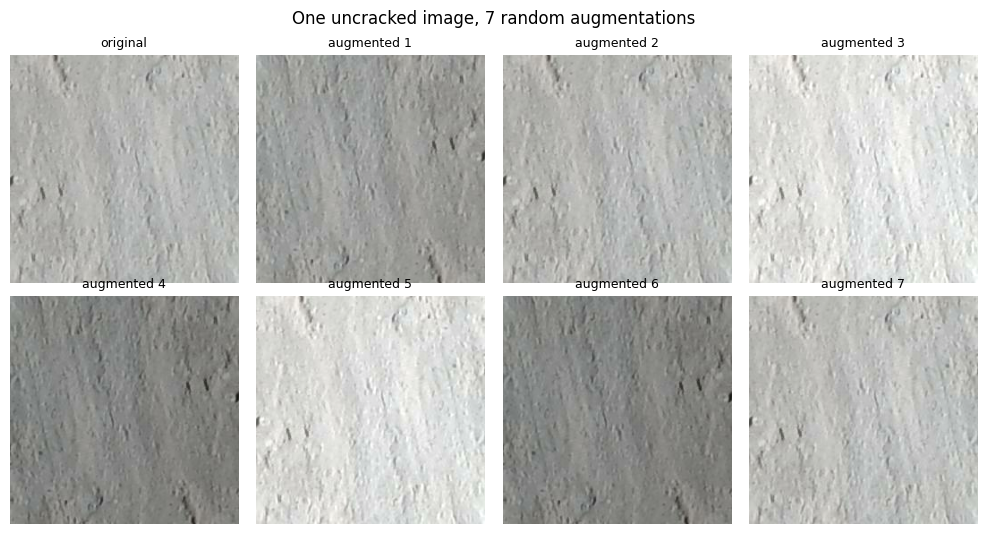

In [ ]:
image = images[0]
label = CLASS_NAMES[int(labels[0, 0])]

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))

for i, ax in enumerate(axes.flat):
    shown = image if i == 0 else data_augmentation(image[tf.newaxis], training=True)[0]
    ax.imshow(np.clip(shown.numpy(), 0, 255).astype("uint8"))
    ax.set_title("original" if i == 0 else f"augmented {i}", fontsize=9)
    ax.axis("off")

fig.suptitle(f"One {label} image, 7 random augmentations")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

- Augmentation check: flips + ±20% brightness/contrast produce realistic variations (shadow-like to sunlit);
  dark augmented images of both classes counteract the brightness bias found in the EDA.


## Baseline CNN (from scratch)


In [ ]:
def build_baseline_cnn():
    """Small 4-block CNN: conv → pool, filters doubling each block."""
    inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
    x = data_augmentation(inputs)
    x = tf.keras.layers.Rescaling(1.0 / 255)(x)  # 0–255 → 0–1

    for filters in [16, 32, 64, 128]:
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    return tf.keras.Model(inputs, outputs, name="baseline_cnn")


model = build_baseline_cnn()
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,569 (381.13 KB)

 Trainable params: 97,569 (381.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Class weights from the train split: weight = total / (2 × class count)
n_uncracked, n_cracked = 8116, 1417
n_total = n_uncracked + n_cracked

class_weight = {
    0: n_total / (2 * n_uncracked),  # uncracked
    1: n_total / (2 * n_cracked),    # cracked
}
print({k: round(v, 2) for k, v in class_weight.items()})

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

{0: 0.59, 1: 3.36}


In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_pr_auc", mode="max", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "baseline_cnn.keras",
        monitor="val_pr_auc", mode="max", save_best_only=True
    ),
]

In [ ]:
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 182s 589ms/step - accuracy: 0.5005 - loss: 0.6904 - pr_auc: 0.1543 - precision: 0.1521 - recall: 0.5159 - val_accuracy: 0.2143 - val_loss: 0.6768 - val_pr_auc: 0.1572 - val_precision: 0.1548 - val_recall: 0.9605
Epoch 2/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 161s 539ms/step - accuracy: 0.4181 - loss: 0.6866 - pr_auc: 0.1614 - precision: 0.1529 - recall: 0.6422 - val_accuracy: 0.2177 - val_loss: 0.6765 - val_pr_auc: 0.2352 - val_precision: 0.1561 - val_recall: 0.9671
Epoch 3/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 166s 556ms/step - accuracy: 0.5588 - loss: 0.6753 - pr_auc: 0.2524 - precision: 0.1866 - recall: 0.5857 - val_accuracy: 0.8581 - val_loss: 0.6609 - val_pr_auc: 0.2482 - val_precision: 0.8182 - val_recall: 0.0592
Epoch 4/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 155s 518ms/step - accuracy: 0.7893 - loss: 0.6653 - pr_auc: 0.2980 - precision: 0.3032 - recall: 0.3218 - val_accuracy: 0.8611 - val_loss: 0.6568 - val_pr_auc: 0.3352 - val_precision: 0.6389 - val_recall:

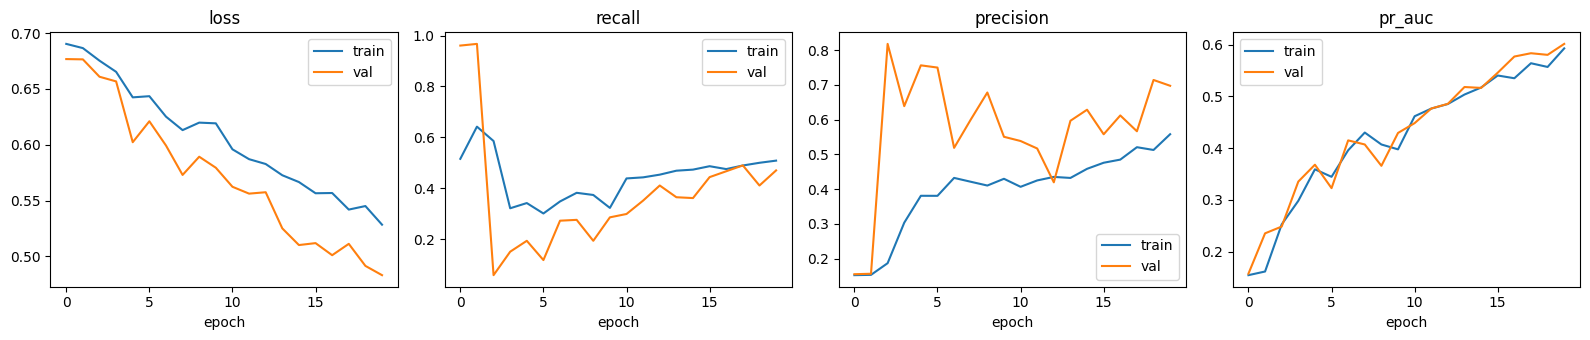

In [ ]:
metrics_to_plot = ["loss", "recall", "precision", "pr_auc"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, metric in zip(axes, metrics_to_plot):
    ax.plot(history.history[metric], label="train")
    ax.plot(history.history[f"val_{metric}"], label="val")
    ax.set_title(metric)
    ax.set_xlabel("epoch")
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "07_baseline_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

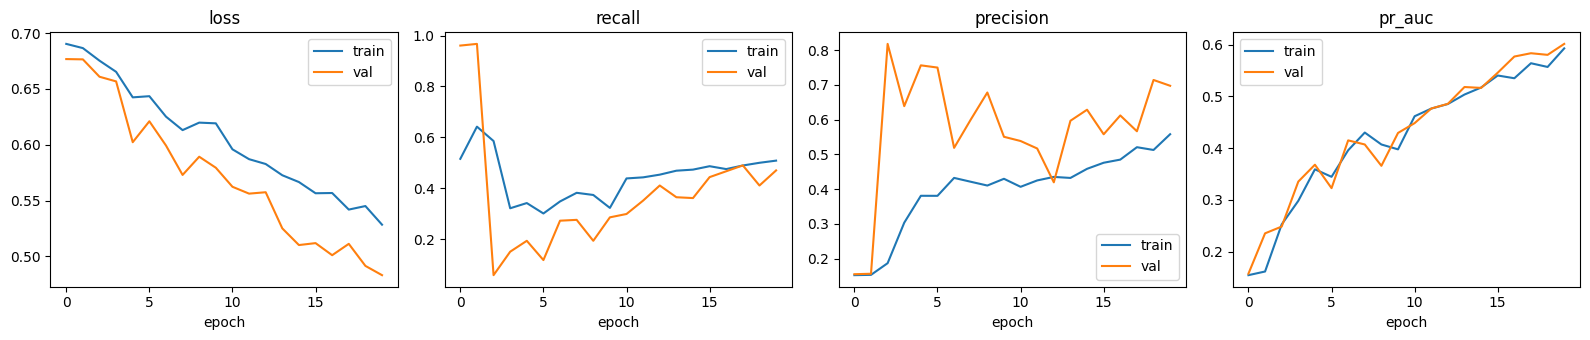

In [ ]:
metrics_to_plot = ["loss", "recall", "precision", "pr_auc"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, metric in zip(axes, metrics_to_plot):
    ax.plot(history.history[metric], label="train")
    ax.plot(history.history[f"val_{metric}"], label="val")
    ax.set_title(metric)
    ax.set_xlabel("epoch")
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "07_baseline_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Baseline CNN v1 – results (validation, epoch 20)

| PR-AUC | Recall | Precision | Accuracy |
| -----: | -----: | --------: | -------: |
|  0.601 |  0.470 |     0.698 |    0.891 |

- ~100k params, class weights, flips + brightness/contrast augmentation; CPU ~3 min/epoch.
- Accuracy 89.1% is only 4 points above the always-"uncracked" baseline (85.1%), yet the model finds 47% of cracks
  → confirms accuracy is misleading.
- Best epoch = last epoch → under-trained; unstable start (recall 0.96 → 0.06 → slow recovery) → add batch normalisation.
